In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [32]:
from sklearn.datasets import make_moons

In [33]:
X, y_true = make_moons(
    n_samples=500,
    noise=0.07,
    random_state=1
)

In [34]:
df = pd.DataFrame(X,columns=["Feature_1","Feature_2"])

In [35]:
df.head()

,Feature_1,Feature_2
0,0.288564,-0.073538
1,0.692118,-0.458926
2,0.858990,0.564246
3,0.587915,0.668611
4,2.017610,0.172116


In [36]:
df.shape

(500, 2)

Text(0, 0.5, 'Feature-2')

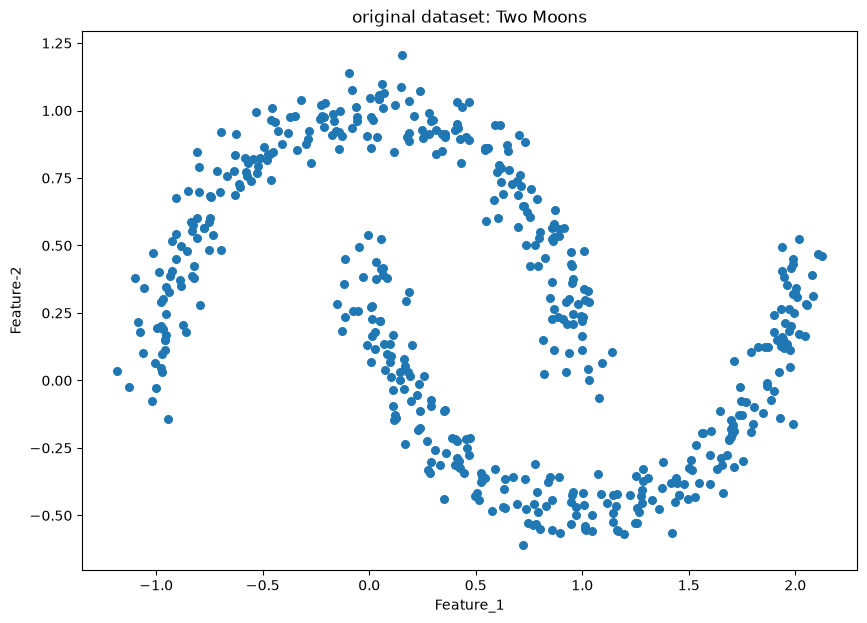

In [37]:
plt.figure(figsize=(10,7))

plt.scatter(X[:,0],X[:,1], s=30)
plt.title("original dataset: Two Moons")
plt.xlabel("Feature_1")
plt.ylabel("Feature-2")

In [38]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [39]:
from sklearn.cluster import DBSCAN

In [40]:
dbscan = DBSCAN(
    eps = 0.20,
    min_samples=5,
    metric="euclidean"
)

In [41]:
labels = dbscan.fit_predict(X_scaled)
labels

array([ 0,  0,  1,  1,  0,  0,  0,  1, -1,  1,  0,  1,  1,  1,  0,  1,  0,
        0,  1,  1,  0,  0,  0,  0,  1,  0,  1,  0,  1,  1,  1,  0,  1,  0,
        0,  1,  0,  1,  0,  0,  0,  0,  0,  1,  0,  0,  0,  0,  0,  1,  1,
        1,  1,  0,  0,  1,  0,  0,  1,  0,  0,  1,  0,  0,  0,  0,  0,  0,
        0,  1,  0,  0,  1,  1,  1,  0,  0,  0,  0,  1,  0,  1,  1,  0,  1,
        1,  0,  0,  0,  0,  0,  0,  0,  1,  0,  1,  1,  1,  1,  1,  1,  0,
        0,  1,  0,  1,  0,  1,  1,  1,  0,  0,  0,  0,  0,  1,  0,  1,  1,
        0,  0,  1,  1,  0,  1,  0,  0,  0,  1,  1,  0,  1,  0,  1,  0,  0,
        0,  0,  0,  1,  1,  1,  1,  0,  1,  0,  1,  1,  1,  1,  1,  1,  0,
        1,  0,  0,  1,  1,  1,  0,  1,  0,  0,  0,  0,  0,  1,  1,  0,  0,
        1,  1,  0,  1,  1,  1,  1,  1,  1,  1,  0,  0,  0,  1,  0,  0,  1,
        1,  1,  0,  1,  1,  0,  0,  1,  0,  1,  0,  1,  0,  0,  0,  0,  1,
        1,  0,  1,  1,  1,  0,  1,  1,  0,  1,  1,  1,  1,  1, -1,  1,  1,
        1,  0,  1,  0,  1

In [42]:
df["Cluster"] = labels

In [43]:
df.head()

,Feature_1,Feature_2,Cluster
0,0.288564,-0.073538,0
1,0.692118,-0.458926,0
2,0.858990,0.564246,1
3,0.587915,0.668611,1
4,2.017610,0.172116,0


In [44]:
df["Cluster"].value_counts().sort_index()

Cluster
-1      2
 0    250
 1    248
Name: count, dtype: int64

In [45]:
n_clusters = len(set(labels) -{-1})

In [46]:
n_clusters

2

In [47]:
n_noise = np.sum(labels == -1)

In [48]:
n_noise

np.int64(2)

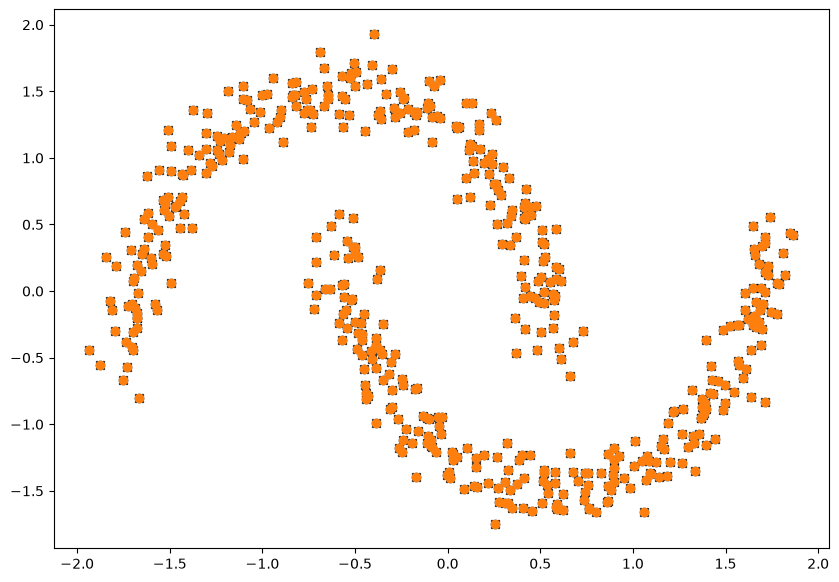

In [49]:
plt.figure(figsize=(10,7))

unique_labels = sorted(set(labels))

for label in unique_labels:
    mask = labels == label

    if label == -1:
        plt.scatter(
            X_scaled[:,0],
            X_scaled[:,1],
            c= "black",
            marker= "x",
            label = "Noise"
        )
    else:
        plt.scatter(
            X_scaled[:,0],
            X_scaled[:,1], 
            label = f"Cluater {label}"
        )

In [50]:
unique_labels

[np.int64(-1), np.int64(0), np.int64(1)]

In [51]:
from sklearn.metrics import silhouette_score
silhouette_score(X_scaled, labels)

0.2791621922263347